# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
)


## Configuration


In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = PROJECT_ROOT / "assets" / "antibiotic_coarsening_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "Simplified categories" #Antibiotic,Class,Simplified categories,High level categories,Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2000
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 2

MIN_CURRENT_PREDICTED_COUNT = 1
MIN_FUTURE_PREDICTED_COUNT = 1
MIN_SI_CHANGE = 0.02
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25
MAX_INTERESTING_PLOTS = 25
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 411
pathogen bg rows: 135
antibiotic bg rows: 189
unified decision rows available for driver analysis: 3,665


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: 'Simplified categories'. Mapped 245 antibiotics into 15 groups.
AMR yearly mapping coverage: 100.00%
Antibiotic background mapping coverage: 100.00%
Unified decision mapping coverage: 100.00%
model yearly rows: 300
model pathogen-antibiotic rows: 19
model antibiotic values: 4
model antibiotic background rows: 108
model unified decision rows: 3,352


,pathogen,antibiotic,year,pmids,count
0,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2010,[19406247],1
1,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2012,[23072056],1
2,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2014,[24320797],1
3,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2015,[24875330],1
4,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2016,[27536994],1
5,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2017,[29151897],1
6,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2018,[29802886],1
7,Clostridioides difficile,Macrolides,2017,[28399946],1
8,Clostridioides difficile,Macrolides,2022,[33818323],1
9,Clostridioides difficile,Macrolides,2023,[36958645],1


## Build Yearly SI Dataset


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [6]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print(f"SI rows: {len(si_df):,}")
print(f"SI pairs: {si_df[['pathogen','antibiotic']].drop_duplicates().shape[0]:,}")
si_df.head(10)


SI rows: 300
SI pairs: 19


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2010,[19406247],1,522,148,0.30103,2.718502,2.173186,-0.036309,0.000000,0.337339
1,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2012,[23072056],1,714,169,0.30103,2.854306,2.230449,0.070298,0.175704,0.230732
2,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2014,[24320797],1,951,180,0.30103,2.978637,2.257679,0.157716,0.437860,0.143314
3,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2015,[24875330],1,1030,231,0.30103,3.013259,2.365488,0.222564,0.669414,0.078466
4,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2016,[27536994],1,1070,236,0.30103,3.029789,2.374748,0.236466,0.723719,0.064564
5,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2017,[29151897],1,1030,250,0.30103,3.013259,2.399674,0.236380,0.723375,0.064650
6,Clostridioides difficile,Beta-lactamase-inhibitors/combinations,2018,[29802886],1,1141,241,0.30103,3.057666,2.383815,0.257264,0.808272,0.043766
7,Clostridioides difficile,Macrolides,2017,[28399946],1,1030,482,0.30103,3.013259,2.683947,0.207459,0.612349,0.093571
8,Clostridioides difficile,Macrolides,2022,[33818323],1,1066,978,0.30103,3.028164,2.990783,0.340622,1.190897,-0.039592
9,Clostridioides difficile,Macrolides,2023,[36958645],1,1034,781,0.30103,3.014940,2.893207,0.293061,0.963636,0.007969


## Rank Reliable Future High-Interest Pairs


In [7]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ],
    head=30,
)


[1/19] ranking Clostridioides difficile vs Beta-lactamase-inhibitors/combinations
[2/19] ranking Clostridioides difficile vs Macrolides
[3/19] ranking Clostridioides difficile vs Penicillins
[4/19] ranking Haemophilus influenzae vs Aminocyclitols/Aminoglycosides
[5/19] ranking Haemophilus influenzae vs Beta-lactamase-inhibitors/combinations
[6/19] ranking Haemophilus influenzae vs Macrolides
[7/19] ranking Haemophilus influenzae vs Penicillins
[8/19] ranking Klebsiella pneumoniae vs Aminocyclitols/Aminoglycosides
[9/19] ranking Klebsiella pneumoniae vs Beta-lactamase-inhibitors/combinations
[10/19] ranking Klebsiella pneumoniae vs Macrolides
[11/19] ranking Klebsiella pneumoniae vs Penicillins
[12/19] ranking Mycobacterium tuberculosis vs Aminocyclitols/Aminoglycosides
[13/19] ranking Mycobacterium tuberculosis vs Beta-lactamase-inhibitors/combinations
[14/19] ranking Mycobacterium tuberculosis vs Macrolides
[15/19] ranking Mycobacterium tuberculosis vs Penicillins
[16/19] ranking Salm

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Macrolides,0.049413,0.131648,7.831428,15.540829,382.302780
1,Haemophilus influenzae,Beta-lactamase-inhibitors/combinations,0.023872,0.051358,4.088986,4.727814,NaN
2,Salmonella enterica,Macrolides,0.019736,0.035625,23.050564,30.963240,53.395356
3,Haemophilus influenzae,Penicillins,0.018371,0.033785,14.574449,15.834398,NaN
4,Klebsiella pneumoniae,Penicillins,0.017286,0.028484,72.060464,105.592333,105.609659
5,Mycobacterium tuberculosis,Aminocyclitols/Aminoglycosides,0.009345,0.022086,2.459235,2.767458,49.567551


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [8]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "driver_recent_total",
        "driver_count_change",
        "driver_dominant_category",
        "driver_fastest_growing_category",
        "driver_weak_signal_share",
        "driver_manual_review_share",
    ],
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations_simplified_categories.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Klebsiella pneumoniae,Macrolides,0.049413,0.131648,7.831428,15.540829,20,13,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,1.000000
1,Haemophilus influenzae,Beta-lactamase-inhibitors/combinations,0.023872,0.051358,4.088986,4.727814,1,-18,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,1.000000
2,Salmonella enterica,Macrolides,0.019736,0.035625,23.050564,30.963240,87,57,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.965517
3,Haemophilus influenzae,Penicillins,0.018371,0.033785,14.574449,15.834398,14,-41,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_EFFECTIVENESS,0.0,0.714286
4,Klebsiella pneumoniae,Penicillins,0.017286,0.028484,72.060464,105.592333,269,170,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.817844
5,Mycobacterium tuberculosis,Aminocyclitols/Aminoglycosides,0.009345,0.022086,2.459235,2.767458,2,-3,DIAGNOSTIC_STEWARDSHIP,DIAGNOSTIC_STEWARDSHIP,0.0,0.500000


## Plot Category Driver Curves


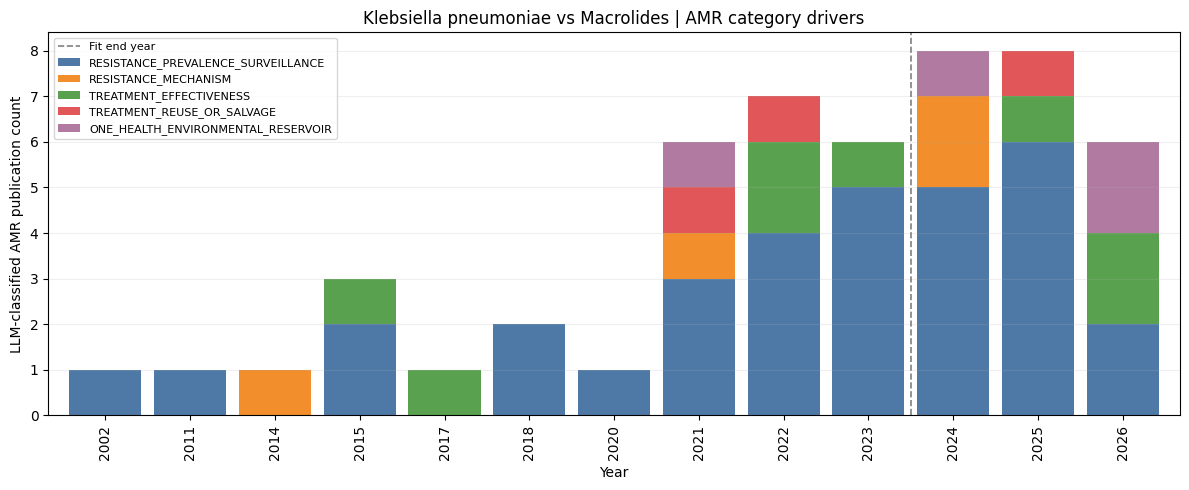

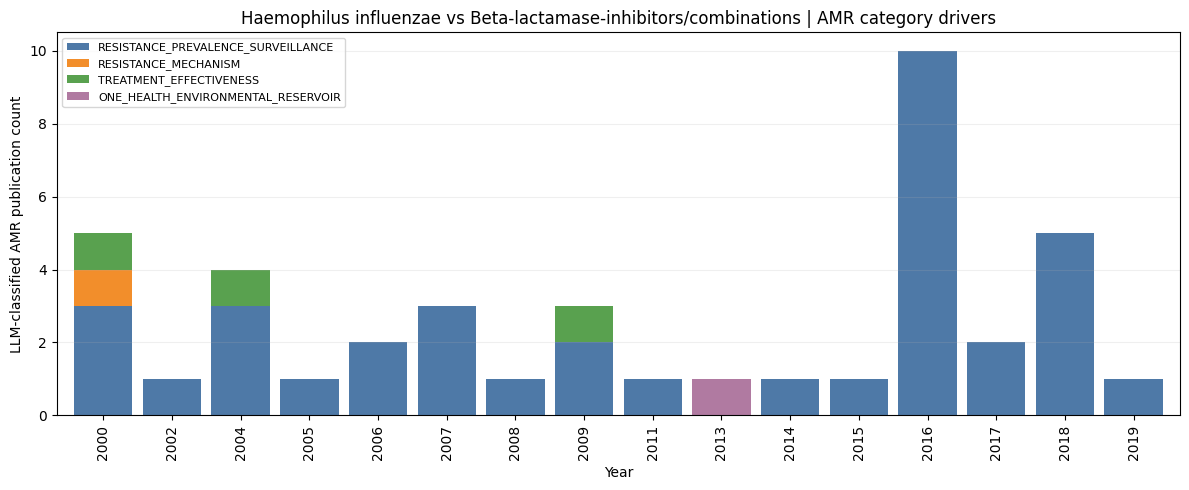

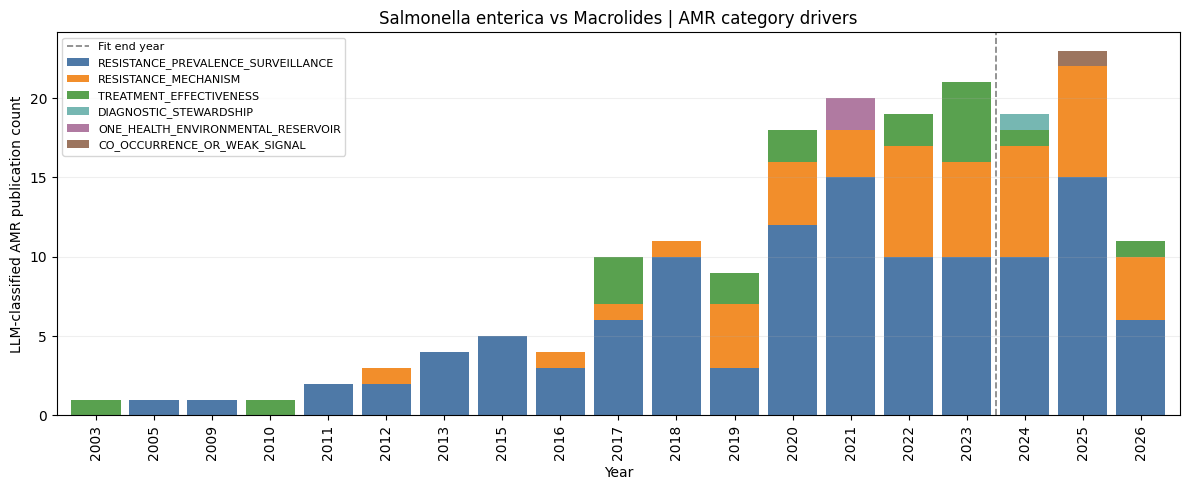

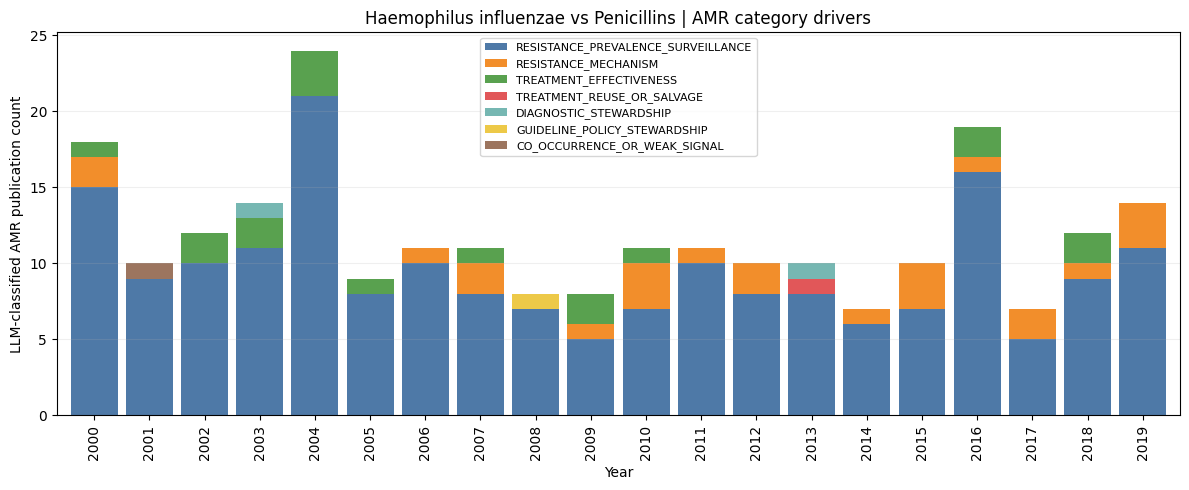

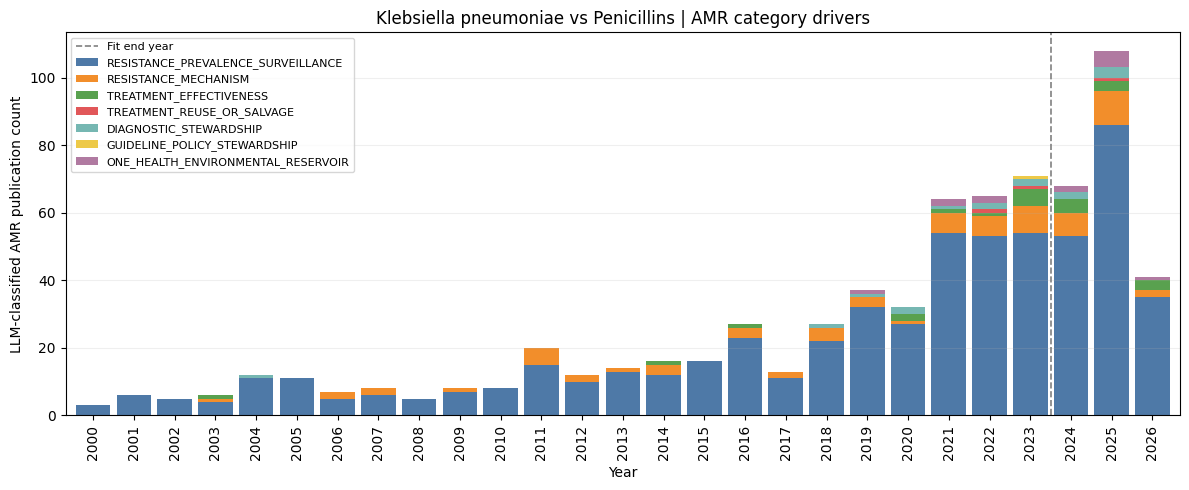

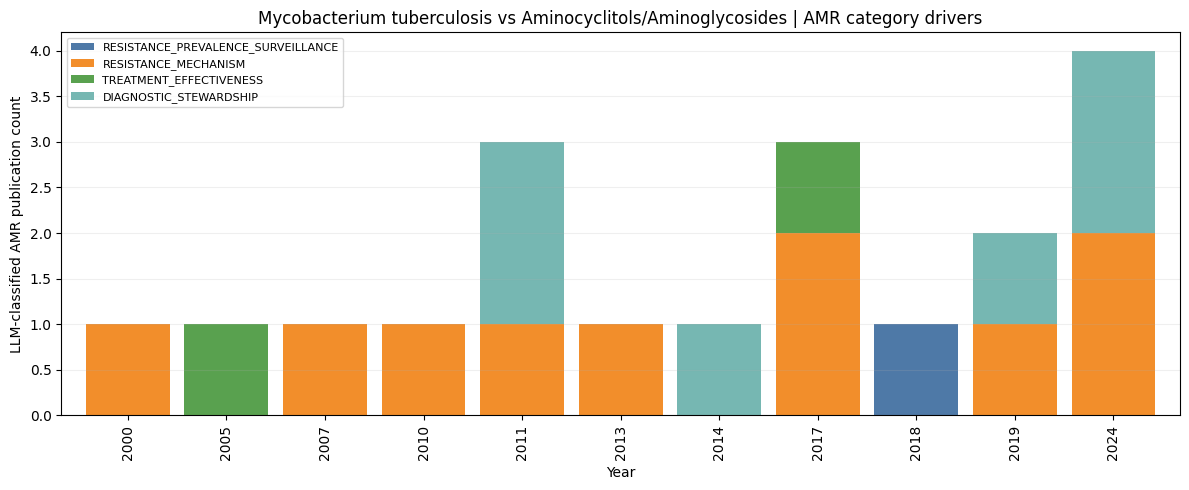

Saved 6 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots_simplified_categories
Displayed 6 category driver plots inline.


In [9]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


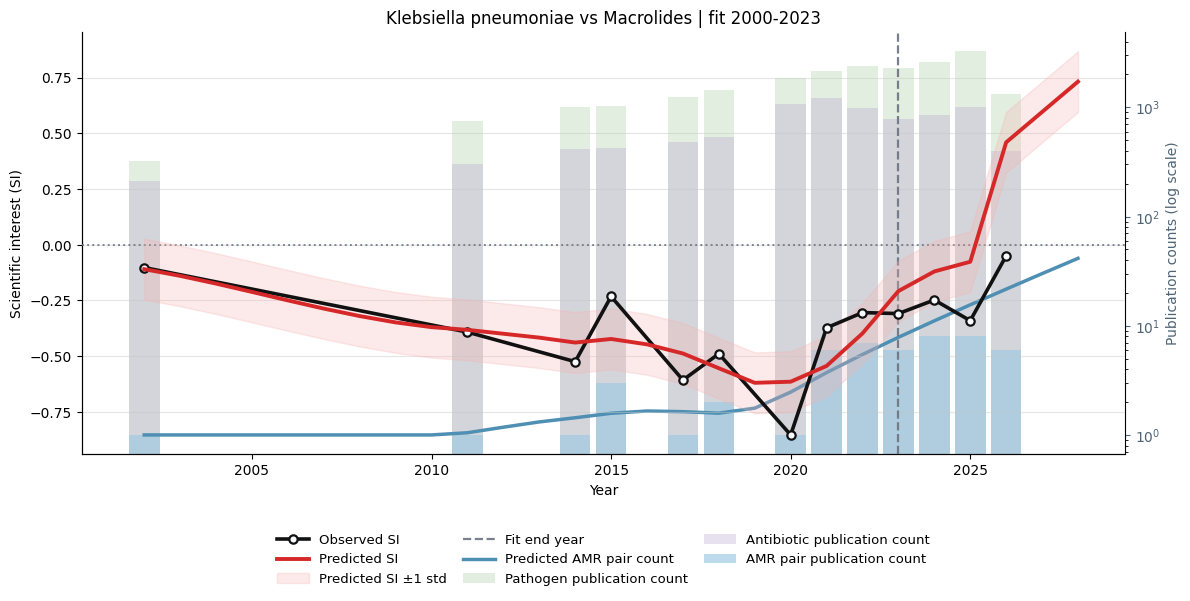

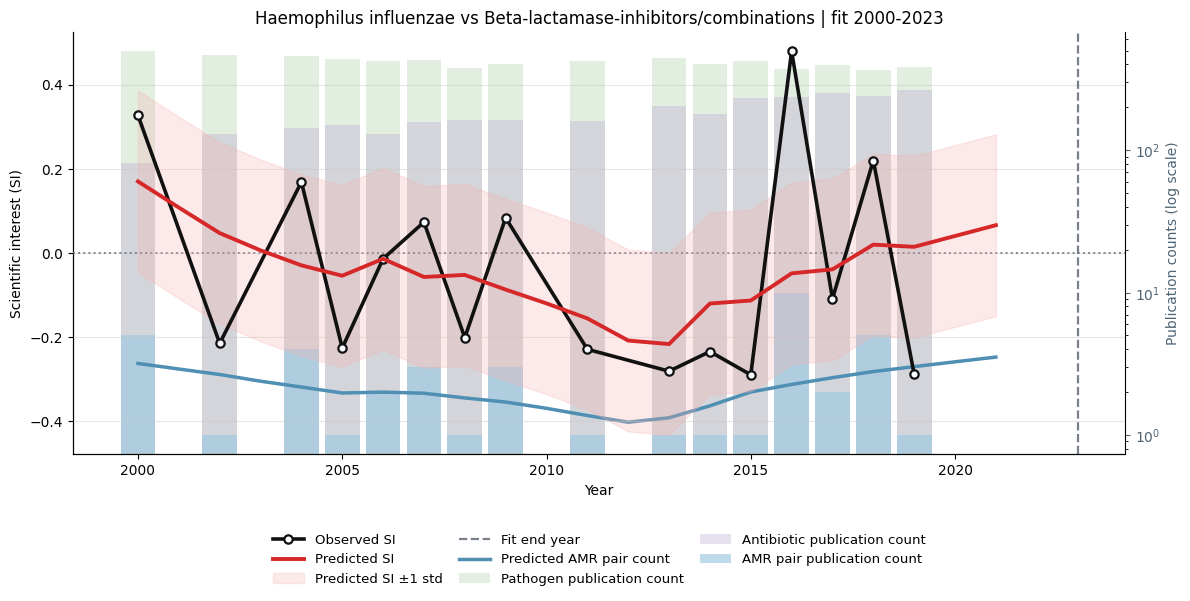

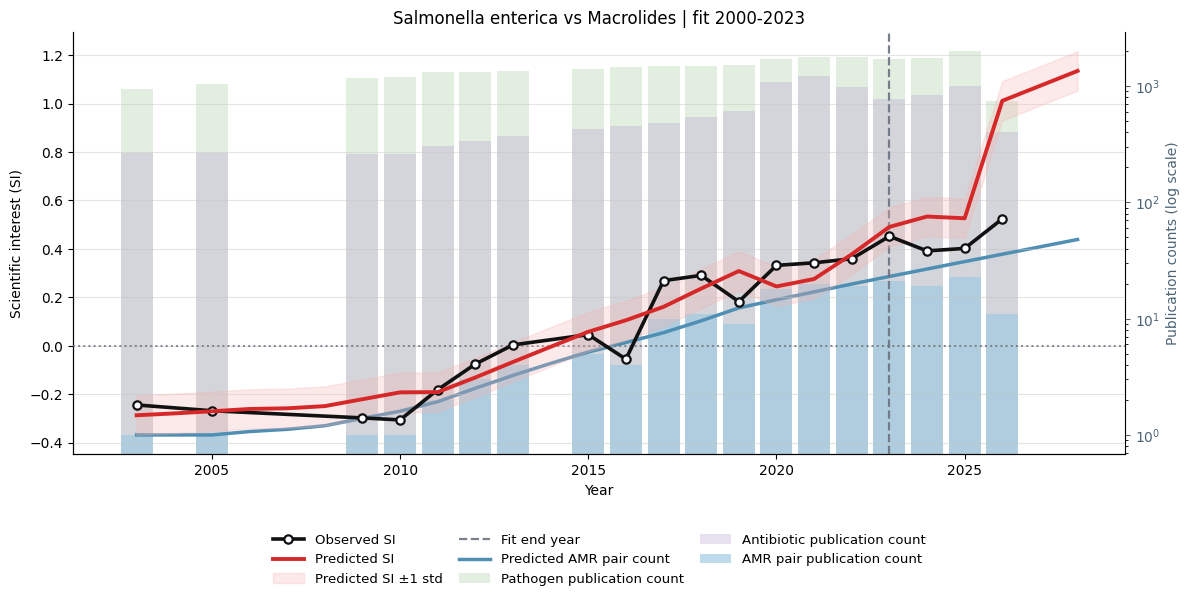

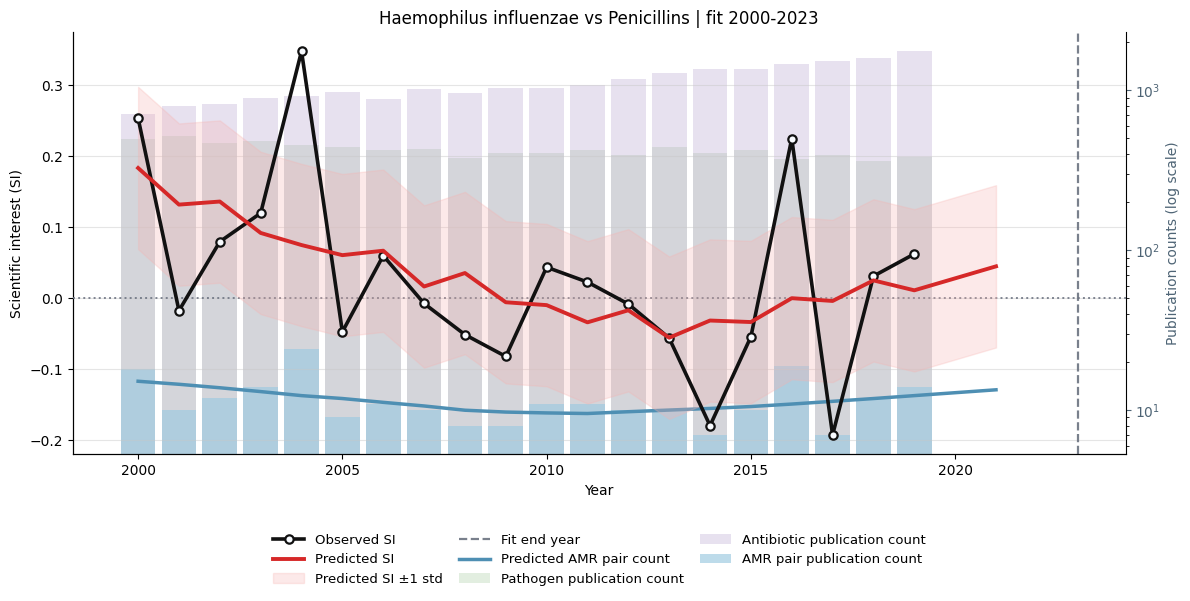

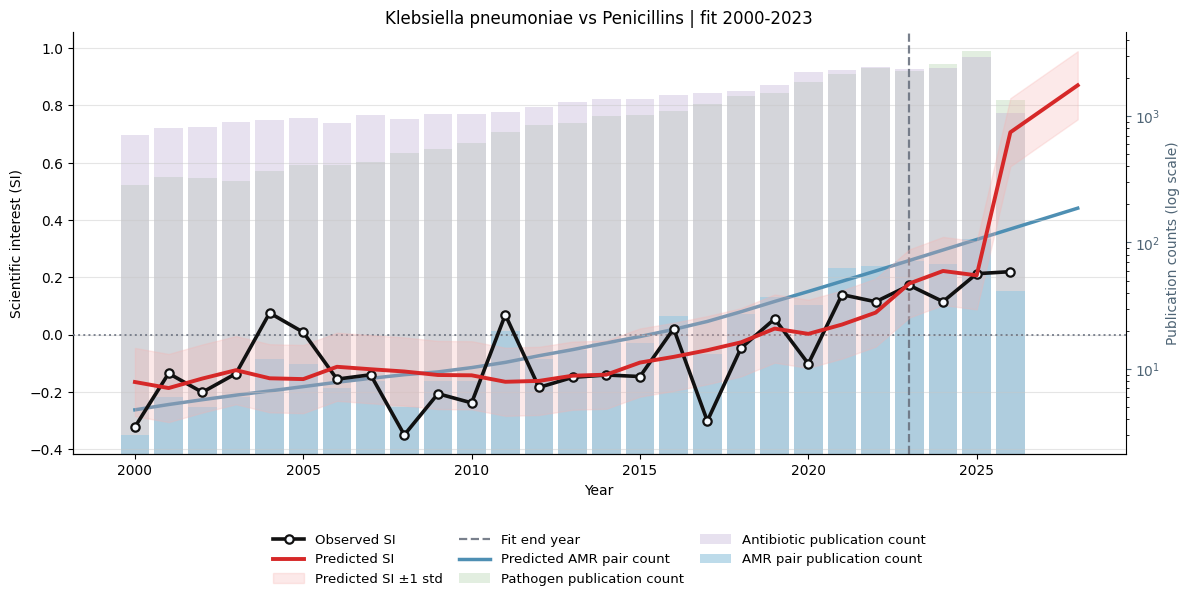

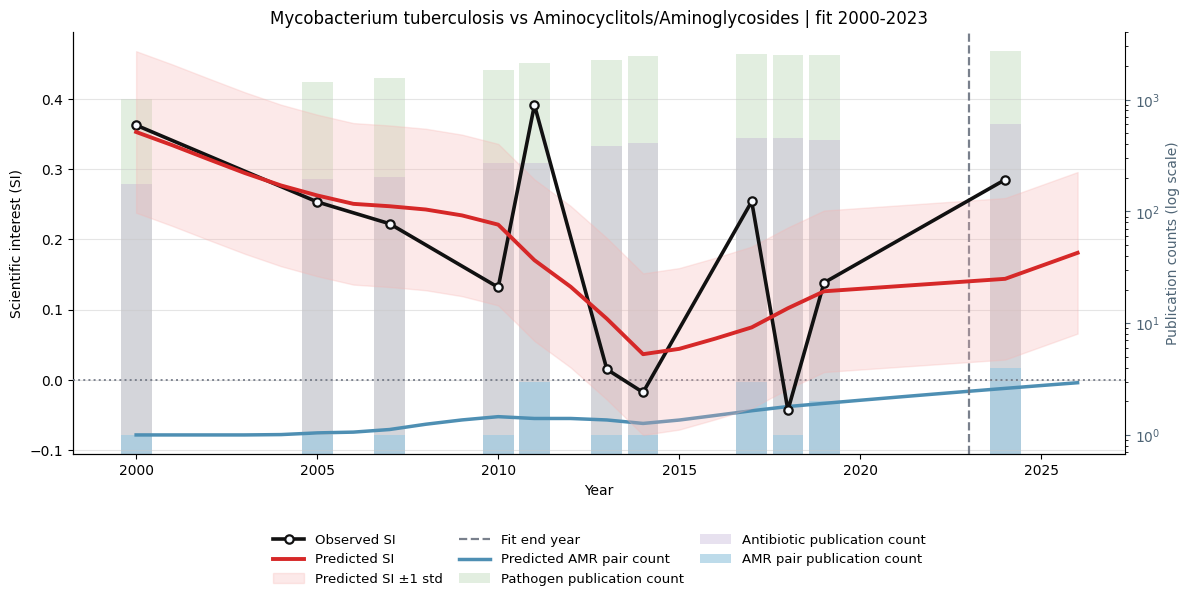

Saved 6 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots_simplified_categories
Displayed 6 plots inline.


In [10]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
